In [1]:

import numpy as np
import matplotlib.pyplot as plt
import os
import torch
import pandas as pd
from adabmDCA.fasta import get_tokens, import_from_fasta
from adabmDCA.stats import get_correlation_two_points, get_freq_single_point, get_freq_two_points
from annadca.rbm import get_rbm
from annadca.dataset import annaDataset
from annadca.utils.analysis import get_eigenvalues_history
from annadca.plot import plot_PCA
from adabmDCA.utils import resample_sequences
import seaborn as sns
sns.set(style="whitegrid")

plt.rcParams.update({'font.size': 14,
                     'text.usetex': True})

In [2]:
fname_train = "../data/SAM/random_split/SAM.train.csv"
fname_test = "../data/SAM/random_split/SAM.test.csv"
fname_all = "../data/SAM/SAM_all.csv"
checkpoint_dir = "../models/SAM/random_split/RBM_checkpoints"
fname_model = os.path.join(checkpoint_dir, "model_update_20000.pt")

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32

In [4]:
# Import dataset
tokens = get_tokens("rna")
dataset = annaDataset(
    path_data=fname_all,
    column_names="header",
    column_sequences="sequence",
    column_labels="label",
    alphabet=tokens,
    path_weights=None,
    no_reweighting=False,
    continuous_labels=True,
    is_binary=False,
    device=device,
    dtype=dtype,
)

train_dataset = annaDataset(
    path_data=fname_train,
    column_names="header",
    column_sequences="sequence",
    column_labels="label",
    alphabet=tokens,
    path_weights=None,
    no_reweighting=False,
    continuous_labels=True,
    is_binary=False,
    device=device,
    dtype=dtype,
)

test_dataset = annaDataset(
    path_data=fname_test,
    column_names="header",
    column_sequences="sequence",
    column_labels="label",
    alphabet=tokens,
    path_weights=None,
    no_reweighting=False,
    continuous_labels=True,
    is_binary=False,
    device=device,
    dtype=dtype,
)

Filtered out 0 sequences with unknown letters. Remaining sequences: 9693.
Filtered out 0 sequences with unknown letters. Remaining sequences: 8723.
Filtered out 0 sequences with unknown letters. Remaining sequences: 970.


### Linear regression

Pearson score on training set: 0.7514
Pearson score on test set: 0.7636


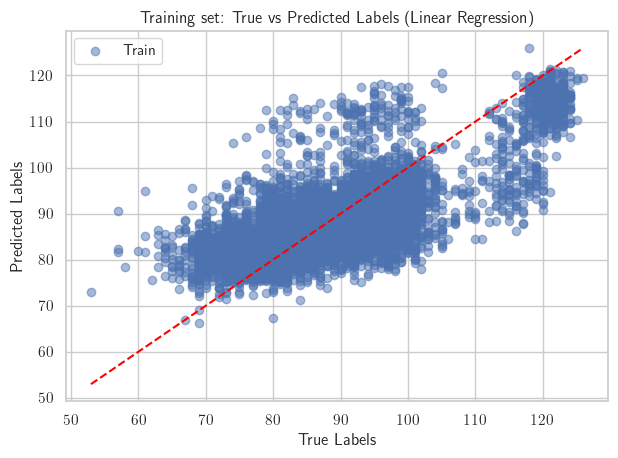

In [5]:
from sklearn.linear_model import LinearRegression

X_train = train_dataset.data_one_hot.view(len(train_dataset.data_one_hot), -1).cpu().numpy()
X_test = test_dataset.data_one_hot.view(len(test_dataset.data_one_hot), -1).cpu().numpy()
y_train = train_dataset.unstandardize_labels(train_dataset.labels_one_hot).cpu().numpy()[:, 0]
y_test = test_dataset.unstandardize_labels(test_dataset.labels_one_hot).cpu().numpy()[:, 0]

model = LinearRegression()
model.fit(X_train, y_train)
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

print(f"Pearson score on training set: {np.corrcoef(y_train, y_pred_train)[0, 1]:.4f}")
print(f"Pearson score on test set: {np.corrcoef(y_test, y_pred_test)[0, 1]:.4f}")

plt.scatter(y_train, y_pred_train, alpha=0.5, label='Train')
x = np.linspace(min(y_train), max(y_train), 100)
plt.plot(x, x, color='red', linestyle='--')
plt.xlabel("True Labels")
plt.ylabel("Predicted Labels")
plt.title("Training set: True vs Predicted Labels (Linear Regression)")
plt.legend()
plt.tight_layout()

### Import the RBM model

In [6]:
# Load the model and the chains
checkpoint = torch.load(fname_model, map_location=device)
rbm = get_rbm(
    visible_type="potts",
    hidden_type="bernoulli",
    visible_shape=checkpoint["model_state_dict"]["weight_matrix"].shape[0:2],
    hidden_shape=checkpoint["model_state_dict"]["weight_matrix"].shape[2],
    num_classes=1,
    continuous_label=True,
)
rbm.load_state_dict(checkpoint["model_state_dict"])
rbm.to(device=device, dtype=dtype)

AnnaRBM(visible_layer=PottsLayer(shape=torch.Size([108, 5]), device=cuda:0, dtype=torch.float32), hidden_layer=BernoulliLayer(shape=torch.Size([500]), device=cuda:0, dtype=torch.float32), num_classes=torch.Size([1]), shape=torch.Size([108, 5, 500]))

### Import the bmDCA model

In [7]:
from adabmDCA import load_params
from adabmDCA.statmech import compute_energy

fname_params_bmDCA = "../models/SAM/bmDCA/bmDCA_params.dat"
params_DCA = load_params(fname_params_bmDCA, tokens=tokens, device=device, dtype=dtype)

### Compare energies on the natural data

/tmp/ipykernel_2006807/3590219393.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  g.ax_joint.legend()


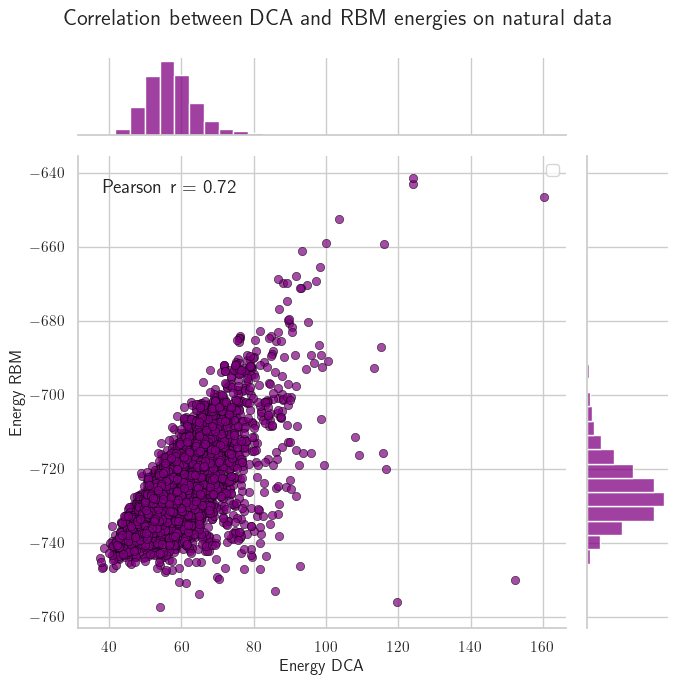

In [8]:
# compare energies on natural data
df_natural = pd.DataFrame({
    "Energy DCA": compute_energy(dataset.data_one_hot, params_DCA).cpu().numpy(),
    "Energy RBM": rbm.compute_energy_visibles_labels(dataset.data_one_hot, dataset.labels_one_hot).cpu().numpy(),
})
correlation_natural = np.corrcoef(df_natural["Energy DCA"], df_natural["Energy RBM"])[0, 1]

g = sns.jointplot(
    data=df_natural,
    x="Energy DCA",
    y="Energy RBM",
    kind="scatter",
    height=7,
    alpha=0.7,
    edgecolor='black',
    marginal_kws=dict(bins=30, fill=True),
    color='purple',
)
g.set_axis_labels("Energy DCA", "Energy RBM")
g.ax_joint.annotate(f"Pearson r = {correlation_natural:.2f}", xy=(0.05, 0.95), xycoords='axes fraction', fontsize=14, verticalalignment='top')
g.fig.suptitle("Correlation between DCA and RBM energies on natural data", fontsize=16)
g.ax_joint.legend()
g.fig.tight_layout()

### Wild-type selection

In [9]:
# Fit the PCA on all the data
from sklearn.decomposition import PCA
from adabmDCA.utils import resample_sequences

seqs_fit_pca = resample_sequences(
    dataset.data_one_hot,
    weights=dataset.weights,
    nextract=5 * len(dataset),
)
seqs_fit_pca = seqs_fit_pca.view(len(seqs_fit_pca), -1).cpu().numpy()
pca = PCA(n_components=2)
pca.fit(seqs_fit_pca)

data_proj = pca.transform(dataset.data_one_hot.view(len(dataset), -1).cpu().numpy())
labels_data = dataset.unstandardize_labels(dataset.labels_one_hot).cpu().numpy()[:, 0]

In [10]:
wt_idx = 11  # Index of the wild-type sequence
wt = dataset.data_one_hot[wt_idx]
wt_proj = pca.transform(wt.view(1, -1).cpu().numpy())
wt_label = dataset.unstandardize_labels(dataset[wt_idx]["label"]).item()
energy_wt = compute_energy(wt.unsqueeze(0), params_DCA).item()
print(f"Wild-type label: {wt_label}")
print(f"Wild-type energy: {energy_wt}")

Wild-type label: 84.0
Wild-type energy: 67.76214599609375


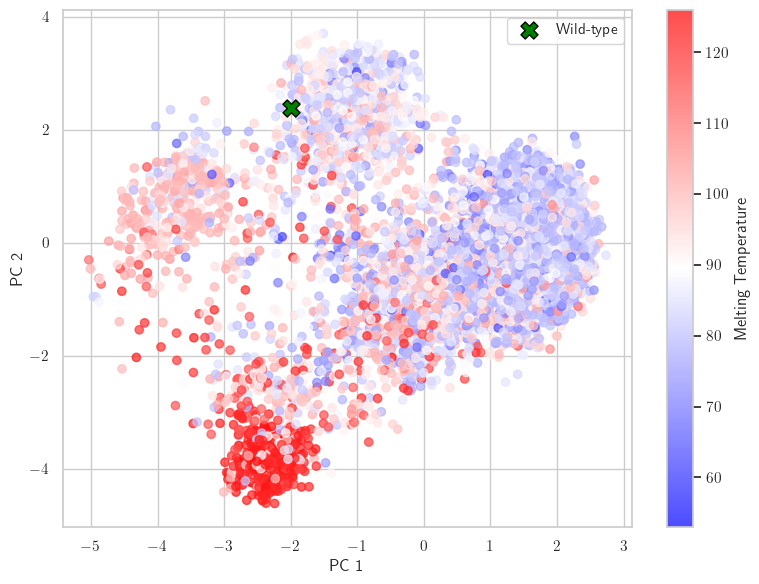

In [11]:
import seaborn as sns
sns.set(style="whitegrid")

plt.figure(figsize=(8, 6))
scatter = plt.scatter(data_proj[:, 0], data_proj[:, 1], c=labels_data, cmap='bwr', alpha=0.7)
plt.scatter(wt_proj[0, 0], wt_proj[0, 1], color='green', s=150, edgecolor='black', label='Wild-type', marker='X')
plt.legend()
plt.colorbar(scatter, label='Melting Temperature')
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.tight_layout()

### Mutate the wild type to improve thermostability

In [12]:
def plot_summary(
    samples_pca: np.ndarray,
    wild_type_pca: np.ndarray,
    data_pca: np.ndarray,
    data_labels: np.ndarray,
    distances: np.ndarray,
    energies: np.ndarray,
    sample_labels: np.ndarray,
    energy_wt: float,
    label_wt: float,
    title: str,
):
    fig, ax = plt.subplots(1, 3, figsize=(18, 5), dpi=100)
    ax = ax.flatten()

    idx = np.argsort(distances)[::-1]

    # Scatter plot PCA
    ax[0].scatter(data_pca[:, 0], data_pca[:, 1], label='Data', alpha=0.5, c=data_labels, cmap='bwr')
    sc = ax[0].scatter(samples_pca[idx, 0], samples_pca[idx, 1], c=distances[idx], cmap='tab20b', label='Samples', edgecolor='black', lw=0.5, s=30)
    ax[0].scatter(wild_type_pca[:, 0], wild_type_pca[:, 1], marker="X", s=200, c='deeppink', label='Wild Type', edgecolor='black')
    ax[0].legend()
    ax[0].set_xlabel("PCA 1")
    ax[0].set_ylabel("PCA 2")
    cbar = plt.colorbar(sc, ax=ax[0])
    cbar.set_label(r"Distance from Wild Type")
    
    # Histogram of distances
    ud, uc = np.unique(distances, return_counts=True)
    ax[1].bar(ud, uc, width=0.8, color='skyblue', alpha=0.7, edgecolor='black')
    ax[1].set_xlabel("Hamming Distance from Wild Type")
    
    # Scatter plot of Energy vs Probability
    ax[2].scatter(sample_labels[idx], energies[idx] - energy_wt, c=distances[idx], cmap="tab20b", label=f"Samples")
    ax[2].set_ylabel(r"$\Delta H_{\mathrm{gen}}$")
    ax[2].set_xlabel(r"Melting Temperature")
    ax[2].set_title(f"Phase space")
    ax[2].scatter(label_wt, 0, marker="X", s=200, c='deeppink', label='Wild Type', edgecolor='black')
    ax[2].legend()
    
    cbar = plt.colorbar(sc, ax=ax[2])
    cbar.set_label(r"Distance from WT")


    fig.suptitle(title, fontsize=16)
    fig.tight_layout()

In [13]:
from annadca.rbm import AnnaRBM
from annadca.rbm import get_rbm

def get_biased_model(
    rbm: AnnaRBM,
    gen_strength: float,
    label_strength: float,
    wt_strength: float,
    wt: torch.Tensor,
) -> "AnnaRBM":
    wt = wt.to(device=rbm.weight_matrix.device, dtype=rbm.weight_matrix.dtype)
    biased_rbm = get_rbm(
        visible_type="potts",
        hidden_type="bernoulli",
        visible_shape=rbm.visible_layer.shape,
        hidden_shape=rbm.hidden_layer.shape,
        num_classes=1,
        continuous_label=True,
    )
    biased_rbm.to(device=rbm.weight_matrix.device, dtype=rbm.weight_matrix.dtype)
    biased_rbm.weight_matrix.data.copy_(rbm.weight_matrix * gen_strength)
    biased_rbm.label_matrix.data.copy_(rbm.label_matrix * label_strength)
    for k, v in biased_rbm.visible_layer.named_parameters():
        v.data.copy_(rbm.visible_layer.state_dict()[k] * gen_strength)
        if "bias" in k:
            v.data.copy_(v.data + wt_strength * wt)
    for k, v in biased_rbm.hidden_layer.named_parameters():
        v.data.copy_(rbm.hidden_layer.state_dict()[k] * gen_strength)
    for k, v in biased_rbm.label_layer.named_parameters():
        v.data.copy_(rbm.label_layer.state_dict()[k] * label_strength)
    return biased_rbm

from annadca.utils.functions import batched_mm_right

def predict_continuous_labels(rbm, visible):
    """Approximate predictions of the labels when the label is a Gaussian variable"""
    h = rbm.mean_hidden_activation(visible, torch.tensor([0.], device=visible.device, dtype=visible.dtype).unsqueeze(1))
    I_l = batched_mm_right(rbm.label_matrix, h) # (batch_size, num_classes)
    mean = (I_l + rbm.label_layer.bias) / rbm.label_layer.scale
    return mean.squeeze()

In [54]:
target_label = 120  # Target melting temperature
gen_strength = 1.0  # Generation strength
wt_strength = 2.0  # Strength of the wild-type bias
label_strength = 2.0  # Strength of the label bias
num_steps = 10000  # Number of Gibbs steps
num_samples = 10000

rbm_biased = get_biased_model(
    rbm=rbm,
    gen_strength=gen_strength,
    label_strength=label_strength,
    wt_strength=wt_strength,
    wt=wt,
)

chains_init = wt.repeat(num_samples, 1, 1)
targets = dataset.standardize_labels(torch.full((num_samples, 1), target_label, device=device, dtype=dtype))

In [55]:
#cond_samples = rbm_biased.sample_conditioned(
#    gibbs_steps=num_steps,
#    targets=targets,
#    visible=chains_init,
#)

cond_samples = rbm_biased.sample(
    gibbs_steps=num_steps,
    visible=chains_init,
)

In [56]:
from adabmDCA.dca import get_seqid
distances = (wt.shape[0] - get_seqid(chains_init, cond_samples["visible"])).cpu().numpy()
energies = compute_energy(cond_samples["visible"], params_DCA).cpu().numpy()
labels_pred_rbm = dataset.unstandardize_labels(predict_continuous_labels(rbm, cond_samples["visible"])).cpu().numpy()
labels_pred_lr = model.predict(cond_samples["visible"].view(len(cond_samples["visible"]), -1).cpu().numpy())
labels_pred_rbm_wt = dataset.unstandardize_labels(predict_continuous_labels(rbm, wt.view(1, *wt.shape))).cpu().numpy().item()
labels_pred_lr_wt = model.predict(wt.view(1, -1).cpu().numpy()).item()
energy_wt = compute_energy(wt.unsqueeze(0), params_DCA).item()

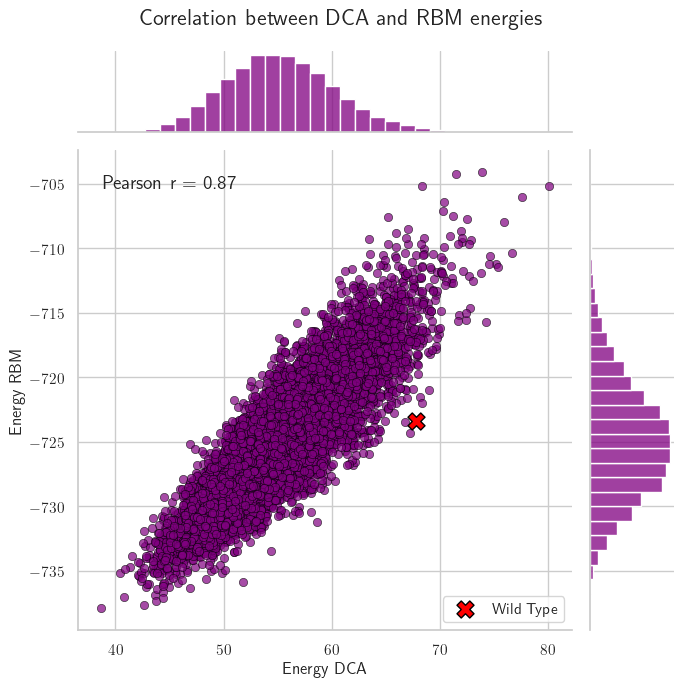

In [57]:
energies_rbm = rbm.compute_energy_visibles_labels(cond_samples["visible"], targets).cpu().numpy()
energy_wt_rbm = rbm.compute_energy_visibles_labels(wt.unsqueeze(0), dataset[wt_idx]["label"].unsqueeze(0)).item()


df = pd.DataFrame({
    "Distance from WT": distances,
    "Energy DCA": energies,
    "Energy RBM": energies_rbm,
})

correlation = np.corrcoef(df["Energy DCA"], df["Energy RBM"])[0, 1]

g = sns.jointplot(
    data=df,
    x="Energy DCA",
    y="Energy RBM",
    kind="scatter",
    height=7,
    alpha=0.7,
    edgecolor='black',
    marginal_kws=dict(bins=30, fill=True),
    color='purple',
)
g.ax_joint.scatter(energy_wt, energy_wt_rbm, color='red', s=150, edgecolor='black', label='Wild Type', marker='X')
g.ax_joint.legend()
g.ax_joint.annotate(f"Pearson r = {correlation:.2f}", xy=(0.05, 0.95), xycoords='axes fraction', fontsize=14, verticalalignment='top')
g.set_axis_labels("Energy DCA", "Energy RBM")
g.fig.suptitle("Correlation between DCA and RBM energies", fontsize=16)
g.fig.tight_layout()

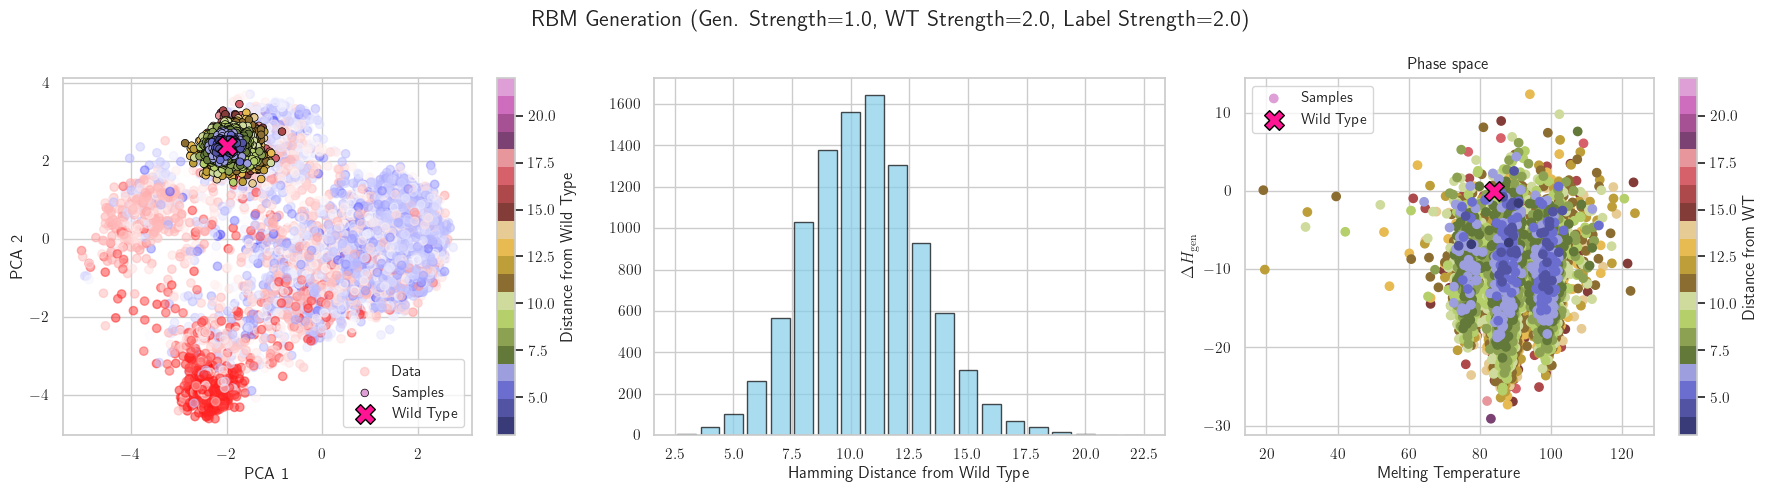

In [58]:
plot_summary(
    samples_pca=pca.transform(cond_samples["visible"].view(len(cond_samples["visible"]), -1).cpu().numpy()),
    wild_type_pca=wt_proj,
    data_pca=data_proj,
    data_labels=labels_data,
    distances=distances,
    energies=energies,
    sample_labels=labels_pred_lr,
    energy_wt=energy_wt,
    label_wt=wt_label,
    title=f"RBM Generation (Gen. Strength={gen_strength}, WT Strength={wt_strength}, Label Strength={label_strength})"
)

In [61]:
# Filter sequences between 10 and 15 mutations from the wild-type
idx_filtered = np.where((distances >= 10) & (distances <= 15))[0]
gen_filtered = cond_samples["visible"][idx_filtered]
labels_filtered = labels_pred_lr[idx_filtered]
energies_filtered = energies[idx_filtered]
distances_filtered = distances[idx_filtered]

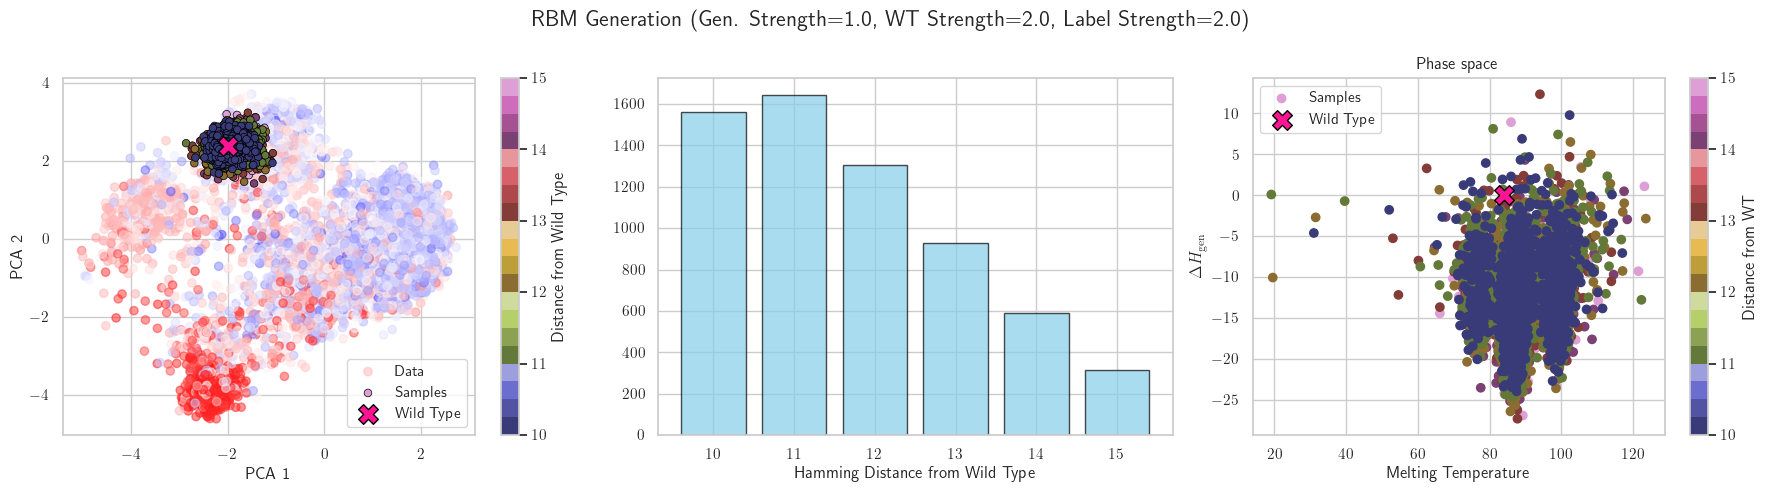

In [62]:
plot_summary(
    samples_pca=pca.transform(gen_filtered.view(len(gen_filtered), -1).cpu().numpy()),
    wild_type_pca=wt_proj,
    data_pca=data_proj,
    data_labels=labels_data,
    distances=distances_filtered,
    energies=energies_filtered,
    sample_labels=labels_filtered,
    energy_wt=energy_wt,
    label_wt=wt_label,
    title=f"RBM Generation (Gen. Strength={gen_strength}, WT Strength={wt_strength}, Label Strength={label_strength})"
)

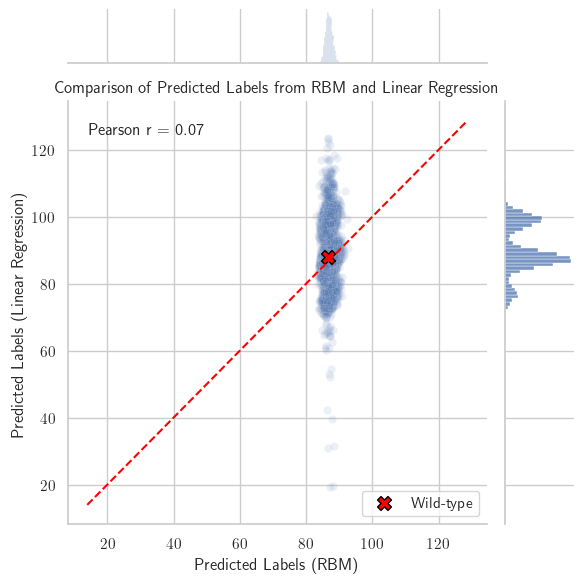

In [59]:
import seaborn as sns
import pandas as pd

import matplotlib.pyplot as plt

# Create a DataFrame for plotting
df = pd.DataFrame({'RBM Label': labels_pred_rbm, 'LR Label': labels_pred_lr})

# Jointplot with marginal histograms
g = sns.jointplot(
    data=df,
    x='RBM Label',
    y='LR Label',
    alpha=0.1,
)

# Add identity line
xlim = g.ax_joint.get_xlim()
ylim = g.ax_joint.get_ylim()
lims = [min(xlim[0], ylim[0]), max(xlim[1], ylim[1])]
g.ax_joint.plot(lims, lims, color='red', linestyle='--')
g.ax_joint.scatter(labels_pred_rbm_wt, labels_pred_lr_wt, color='red', s=100, edgecolor='black', label='Wild-type', marker='X')
g.ax_joint.legend()

# Pearson correlation annotation
corr = np.corrcoef(labels_pred_rbm, labels_pred_lr)[0, 1]
g.ax_joint.annotate(f'Pearson r = {corr:.2f}', xy=(0.05, 0.95), xycoords='axes fraction', fontsize=12, verticalalignment='top')

g.ax_joint.set_xlabel("Predicted Labels (RBM)")
g.ax_joint.set_ylabel("Predicted Labels (Linear Regression)")
g.ax_joint.set_title("Comparison of Predicted Labels from RBM and Linear Regression")

plt.tight_layout()
plt.show()

## Test the generated sequences with the Vienna package

In [63]:
import re
import RNA

def compute_Tm(sequences, tmin=0, tmax=150, tinc=1):
    T_m_list = []
    string_sequences = ["".join(tokens[i] for i in sequence) for sequence in sequences]
    for i, seq in enumerate(string_sequences):
        print(f"Computing Tm for sequence {i+1} of {len(string_sequences)}")
        fc = RNA.fold_compound(seq)
        results = RNA.fold_compound.heat_capacity(fc, tmin, tmax, tinc)
        temperatures = []
        heat_capacities = []
        for result in results:
            # Convert the object to string
            result_str = str(result)
            # Parse the string (assuming format: RNA.RNA.heat_capacity_result(temperature="X", heat_capacity=Y))
            temp_str = float(re.split(r'[ ,"]', str(result))[3])
            hc_str = float(re.split(r'[ ,"]', str(result))[7])

            temperatures.append(temp_str)
            heat_capacities.append(hc_str)

        # Convert to NumPy arrays if needed
        temperatures = np.array(temperatures)
        heat_capacities = np.array(heat_capacities)
        argmax_hc = np.argmax(heat_capacities)
        T_m = temperatures[argmax_hc]
        T_m_list.append(T_m)

    return T_m_list

Computing Tm for sequence 1 of 200
Computing Tm for sequence 2 of 200
Computing Tm for sequence 3 of 200
Computing Tm for sequence 4 of 200
Computing Tm for sequence 5 of 200
Computing Tm for sequence 6 of 200
Computing Tm for sequence 7 of 200
Computing Tm for sequence 8 of 200
Computing Tm for sequence 9 of 200
Computing Tm for sequence 10 of 200
Computing Tm for sequence 11 of 200
Computing Tm for sequence 12 of 200
Computing Tm for sequence 13 of 200
Computing Tm for sequence 14 of 200
Computing Tm for sequence 15 of 200
Computing Tm for sequence 16 of 200
Computing Tm for sequence 17 of 200
Computing Tm for sequence 18 of 200
Computing Tm for sequence 19 of 200
Computing Tm for sequence 20 of 200
Computing Tm for sequence 21 of 200
Computing Tm for sequence 22 of 200
Computing Tm for sequence 23 of 200
Computing Tm for sequence 24 of 200
Computing Tm for sequence 25 of 200
Computing Tm for sequence 26 of 200
Computing Tm for sequence 27 of 200
Computing Tm for sequence 28 of 200
C

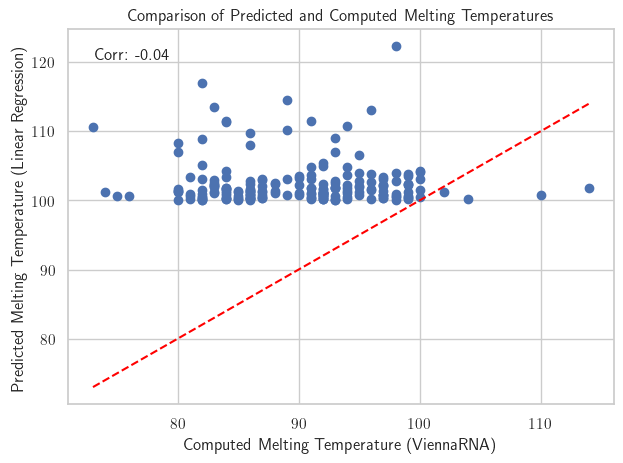

In [64]:
num_test = 200

# keep omly data with predicted label higher or equal to a threshold
th = 100
mask1 = labels_filtered >= th
# keep only data with dca energy lower or equal to wt
mask2 = energies_filtered <= energy_wt
mask = mask1 & mask2
labels_filtered = labels_filtered[mask]
distances_filtered = distances_filtered[mask]
gen_filtered = gen_filtered[mask]
energies_filtered = energies_filtered[mask]

# sort data by increasing distance from wt
distances_sorted_indices = np.argsort(distances_filtered)
labels_filtered = labels_filtered[distances_sorted_indices]
distances_filtered = distances_filtered[distances_sorted_indices]
gen_filtered = gen_filtered[distances_sorted_indices]
energies_filtered = energies_filtered[distances_sorted_indices]

sequences_to_test = gen_filtered[:num_test].argmax(dim=-1).cpu().numpy()
Tm_values = compute_Tm(sequences_to_test, tmin=0, tmax=150, tinc=1)

plt.scatter(Tm_values, labels_filtered[:num_test])
plt.ylabel("Predicted Melting Temperature (Linear Regression)")
plt.xlabel("Computed Melting Temperature (ViennaRNA)")
plt.title("Comparison of Predicted and Computed Melting Temperatures")
x = np.linspace(min(Tm_values), max(Tm_values), 100)
plt.plot(x, x, color='red', linestyle='--')
plt.annotate(f'Corr: {np.corrcoef(Tm_values, labels_filtered[:num_test])[0, 1]:.2f}', xy=(0.05, 0.95), xycoords='axes fraction', fontsize=12,
             horizontalalignment='left', verticalalignment='top')
plt.tight_layout()

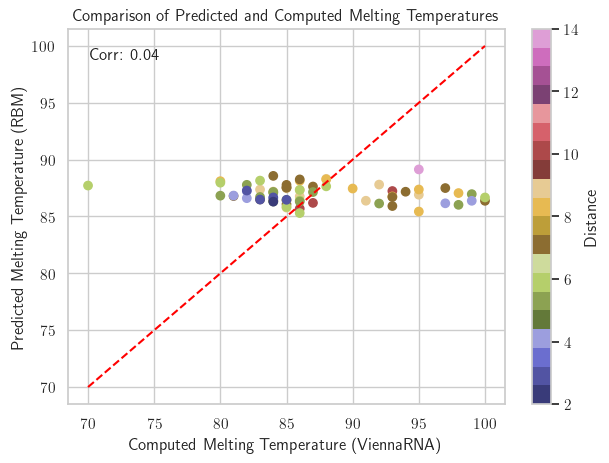

In [127]:
distances_sel = distances[:num_test]
idx = np.argsort(distances_sel)[::-1]
Tm_values = np.array(Tm_values)

plt.scatter(Tm_values[idx], labels_pred_rbm[idx], c=distances[idx], cmap='tab20b')
plt.colorbar(label='Distance')
plt.ylabel("Predicted Melting Temperature (RBM)")
plt.xlabel("Computed Melting Temperature (ViennaRNA)")
plt.title("Comparison of Predicted and Computed Melting Temperatures")
x = np.linspace(min(Tm_values), max(Tm_values), 100)
plt.plot(x, x, color='red', linestyle='--')
plt.annotate(f'Corr: {np.corrcoef(Tm_values, labels_pred_lr[idx])[0, 1]:.2f}', xy=(0.05, 0.95), xycoords='axes fraction', fontsize=12,
             horizontalalignment='left', verticalalignment='top')
plt.tight_layout()

In [66]:
distances_sel = distances_filtered[:num_test]
idx = np.argsort(distances_sel)[::-1]
Tm_values = np.array(Tm_values)[idx]

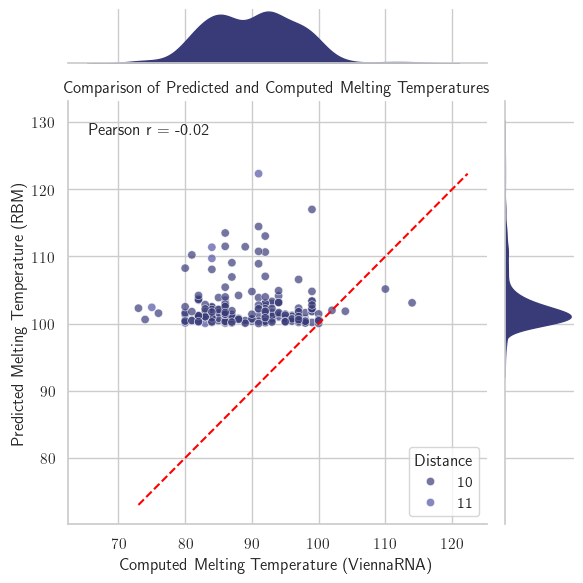

In [68]:
import seaborn as sns
import pandas as pd

# Prepare DataFrame for jointplot
df = pd.DataFrame({
    "Computed Tm (ViennaRNA)": Tm_values[idx],
    "Predicted Tm (RBM)": labels_filtered[idx],
    "Distance": distances_sel[idx].astype(int),
})

# Jointplot with marginal histograms and color by distance
g = sns.jointplot(
    data=df,
    x="Computed Tm (ViennaRNA)",
    y="Predicted Tm (RBM)",
    kind="scatter",
    hue="Distance",
    palette="tab20b",
    marginal_kws=dict(fill=True, color='skyblue', alpha=1.0),
    alpha=0.7
)

# Add identity line
lims = [min(df["Computed Tm (ViennaRNA)"].min(), df["Predicted Tm (RBM)"].min()),
        max(df["Computed Tm (ViennaRNA)"].max(), df["Predicted Tm (RBM)"].max())]
g.ax_joint.plot(lims, lims, color='red', linestyle='--')

# Pearson correlation annotation
corr = np.corrcoef(df["Computed Tm (ViennaRNA)"], df["Predicted Tm (RBM)"])[0, 1]
g.ax_joint.annotate(f'Pearson r = {corr:.2f}', xy=(0.05, 0.95), xycoords='axes fraction', fontsize=12, verticalalignment='top')

g.ax_joint.set_xlabel("Computed Melting Temperature (ViennaRNA)")
g.ax_joint.set_ylabel("Predicted Melting Temperature (RBM)")
g.ax_joint.set_title("Comparison of Predicted and Computed Melting Temperatures")

plt.tight_layout()
plt.show()

## Without biasing the label

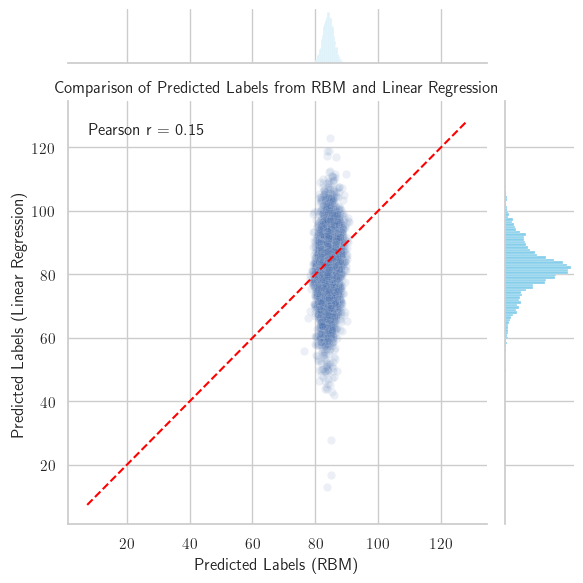

In [184]:
target_label = 100  # Target melting temperature
gen_strength = 1.0  # Generation strength
wt_strength = 2.0  # Strength of the wild-type bias
label_strength = 0.0  # Strength of the label bias
num_steps = 10000  # Number of Gibbs steps
num_samples = 10000

rbm_biased = get_biased_model(
    rbm=rbm,
    gen_strength=gen_strength,
    label_strength=label_strength,
    wt_strength=wt_strength,
    wt=wt,
)

chains_init = wt.repeat(num_samples, 1, 1)
targets = dataset.standardize_labels(torch.full((num_samples, 1), target_label, device=device, dtype=dtype))

cond_samples = rbm_biased.sample(
    gibbs_steps=num_steps,
    visible=chains_init,
)


distances = (wt.shape[0] - get_seqid(chains_init, cond_samples["visible"])).cpu().numpy()
energies = rbm.compute_energy_visibles_labels(cond_samples["visible"], targets).cpu().numpy()
labels_pred_rbm = dataset.unstandardize_labels(predict_continuous_labels(rbm, cond_samples["visible"])).cpu().numpy()
labels_pred_lr = model.predict(cond_samples["visible"].view(len(cond_samples["visible"]), -1).cpu().numpy())
labels_pred_rbm_wt = dataset.unstandardize_labels(predict_continuous_labels(rbm, wt.view(1, *wt.shape))).cpu().numpy().item()
labels_pred_lr_wt = model.predict(wt.view(1, -1).cpu().numpy()).item()
energy_wt = rbm.compute_energy_visibles_labels(wt.unsqueeze(0), dataset[wt_idx]["label"].unsqueeze(0)).item()


# Create a DataFrame for plotting
df = pd.DataFrame({'RBM Label': labels_pred_rbm, 'LR Label': labels_pred_lr})

# Jointplot with marginal histograms
g = sns.jointplot(
    data=df,
    x='RBM Label',
    y='LR Label',
    kind='scatter',
    marginal_kws=dict(fill=True, color='skyblue', alpha=1.0),
    alpha=0.1,
)

# Add identity line
xlim = g.ax_joint.get_xlim()
ylim = g.ax_joint.get_ylim()
lims = [min(xlim[0], ylim[0]), max(xlim[1], ylim[1])]
g.ax_joint.plot(lims, lims, color='red', linestyle='--')

# Pearson correlation annotation
corr = np.corrcoef(labels_pred_rbm, labels_pred_lr)[0, 1]
g.ax_joint.annotate(f'Pearson r = {corr:.2f}', xy=(0.05, 0.95), xycoords='axes fraction', fontsize=12, verticalalignment='top')

g.ax_joint.set_xlabel("Predicted Labels (RBM)")
g.ax_joint.set_ylabel("Predicted Labels (Linear Regression)")
g.ax_joint.set_title("Comparison of Predicted Labels from RBM and Linear Regression")

plt.tight_layout()
plt.show()

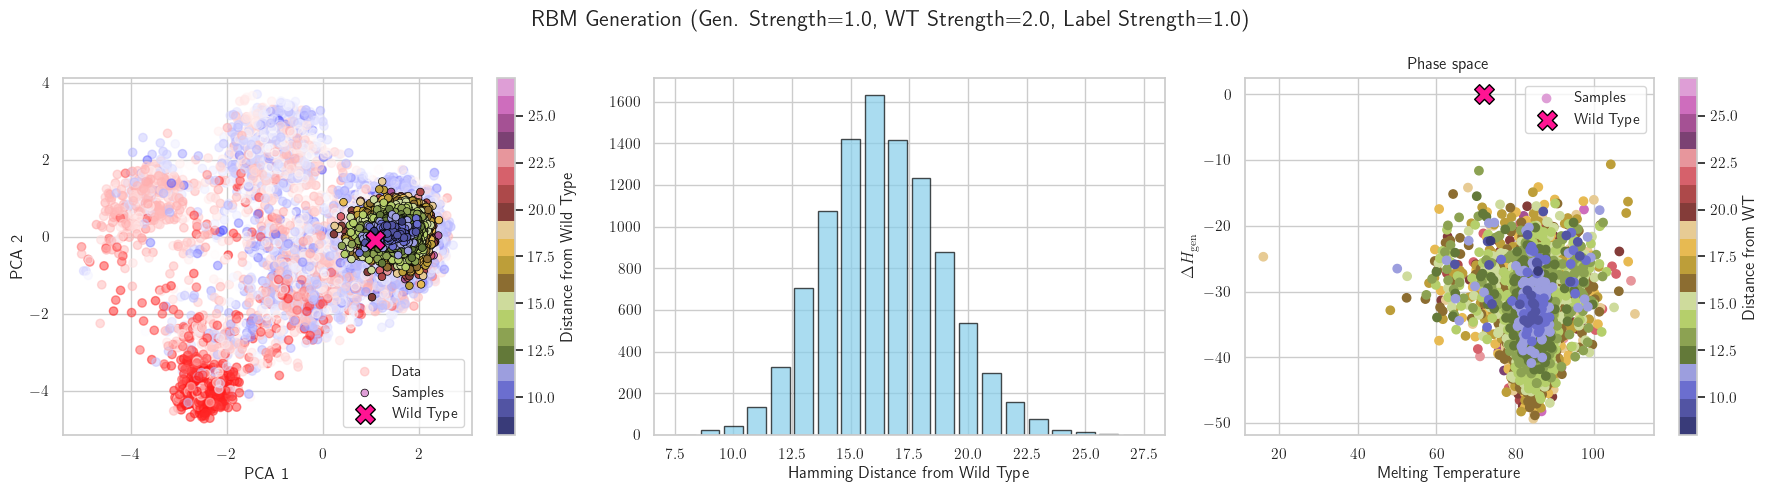

In [182]:
plot_summary(
    samples_pca=pca.transform(cond_samples["visible"].view(len(cond_samples["visible"]), -1).cpu().numpy()),
    wild_type_pca=wt_proj,
    data_pca=data_proj,
    data_labels=labels_data,
    distances=distances,
    energies=energies,
    sample_labels=labels_pred_lr,
    energy_wt=energy_wt,
    label_wt=wt_label,
    title=f"RBM Generation (Gen. Strength={gen_strength}, WT Strength={wt_strength}, Label Strength={label_strength})"
)

## Other stuff

In [332]:
data = train_dataset.data_one_hot
weights = train_dataset.weights.view(-1)

# Load the model and the chains
checkpoint = torch.load(fname_model, map_location=device)
rbm = get_rbm(
    visible_type="potts",
    hidden_type="bernoulli",
    visible_shape=checkpoint["model_state_dict"]["weight_matrix"].shape[0:2],
    hidden_shape=checkpoint["model_state_dict"]["weight_matrix"].shape[2],
    num_classes=1,
    continuous_label=True,
)

rbm.load_state_dict(checkpoint["model_state_dict"])
rbm.to(device=device, dtype=dtype)

chains = checkpoint["chains"]

labels_data = train_dataset.unstandardize_labels(train_dataset.labels_one_hot).cpu().numpy()[:, 0]
labels_chains = train_dataset.unstandardize_labels(chains["label"]).cpu().numpy()[:, 0]

In [52]:
fi = get_freq_single_point(data, weights=weights, pseudo_count=1e-8)
fij = get_freq_two_points(data, weights=weights, pseudo_count=1e-8)
pi = get_freq_single_point(chains["visible"])
pij = get_freq_two_points(chains["visible"])
rho, slope = get_correlation_two_points(fij, pij, fi, pi)
print(f"Correlation: {rho}, Slope: {slope}")

Correlation: 0.9594913125038147, Slope: 0.9737944006919861


In [53]:
print(labels_data.mean(), labels_data.std())
print(train_dataset.unstandardize_labels((rbm.label_layer.bias.data / rbm.label_layer.scale.data)).item(), torch.sqrt(1 / rbm.label_layer.scale.data).item() * train_dataset.labels_std.item())

85.42823 8.654332
82.56278228759766 5.482027109058663


In [54]:
# Project data and chains on the same PCA space
pca = PCA(n_components=2)
data_fit_pca = resample_sequences(data, weights=weights, nextract=2*len(data))
data_flat = data_fit_pca.view(len(data_fit_pca), -1)
pca.fit(data_flat.cpu().numpy())
data_proj = pca.transform(data.view(len(data), -1).cpu().numpy())
chains_proj = pca.transform(chains["visible"].view(len(chains["visible"]), -1).cpu().numpy())

<Figure size 800x800 with 0 Axes>

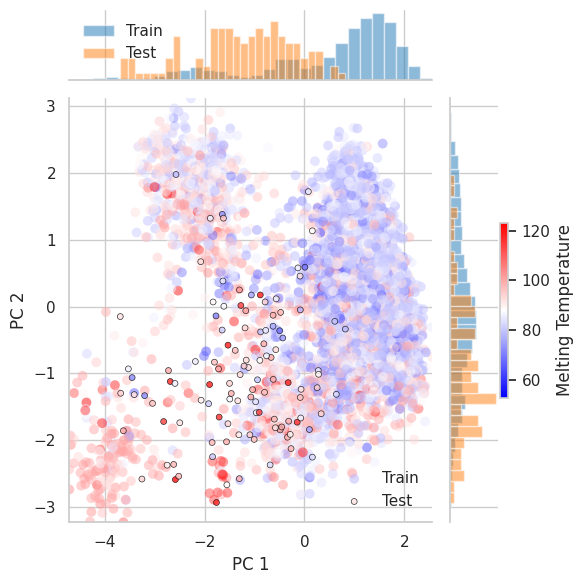

In [72]:
import seaborn as sns
import pandas as pd
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

test_proj = pca.transform(test_dataset.data_one_hot.view(len(test_dataset.data_one_hot), -1).cpu().numpy())
test_labels = test_dataset.unstandardize_labels(test_dataset.labels_one_hot).cpu().numpy()[:, 0]

fig = plt.figure(figsize=(8, 8), dpi=100)

# Put into a single DataFrame if desired (not strictly necessary)
df1 = pd.DataFrame({'x': data_proj[:, 0], 'y': data_proj[:, 1], 'label': labels_data, 'group': 'Train'})
df2 = pd.DataFrame({'x': test_proj[:, 0], 'y': test_proj[:, 1], 'label': test_labels, 'group': 'Test'})
df = pd.concat([df1, df2], ignore_index=True)

# Build a JointGrid for shared axes and custom marginals
sns.set_theme(style="whitegrid")
g = sns.JointGrid(x="x", y="y", data=df, height=6)

# Create a single colormap normalization across both datasets
vmin = df['label'].min()
vmax = df['label'].max()
norm = Normalize(vmin=vmin, vmax=vmax)
cmap = plt.get_cmap("bwr")

# Plot scatter for each dataset separately on the same joint axes
ax = g.ax_joint
sc1 = ax.scatter(df1['x'], df1['y'], c=cmap(norm(df1['label'])), s=50, edgecolor='none', alpha=0.5, label='Train')
sc2 = ax.scatter(df2['x'], df2['y'], c=cmap(norm(df2['label'])), s=18, edgecolor='black', alpha=0.8, label='Test', linewidth=0.5)

ax.legend(frameon=False, loc="best")
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")

# Add a single colorbar representing the continuous variable
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cb = plt.colorbar(sm, ax=g.ax_marg_y, pad=0.02)
cb.set_label("Melting Temperature")

# Marginal histograms for each dataset, overlaid
# Top (x) histogram
g.ax_marg_x.hist(df1['x'], bins=30, density=True, color="#1f77b4", alpha=0.5, label='Train')
g.ax_marg_x.hist(df2['x'], bins=30, density=True, color="#ff7f0e", alpha=0.5, label='Test')
g.ax_marg_x.set_xlim(df['x'].min(), df['x'].max())
g.ax_marg_x.set_ylabel("Density")
g.ax_marg_x.legend(frameon=False, loc="best")

# Right (y) histogram
g.ax_marg_y.hist(df1['y'], bins=30, density=True, color="#1f77b4", alpha=0.5, orientation="horizontal")
g.ax_marg_y.hist(df2['y'], bins=30, density=True, color="#ff7f0e", alpha=0.5, orientation="horizontal")
g.ax_marg_y.set_ylim(df['y'].min(), df['y'].max())
g.ax_marg_y.set_xlabel("Density")

plt.tight_layout()
plt.show()

<Figure size 800x800 with 0 Axes>

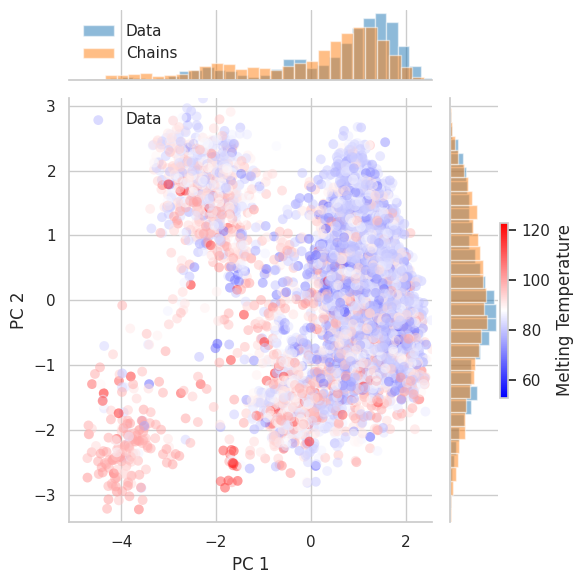

<Figure size 800x800 with 0 Axes>

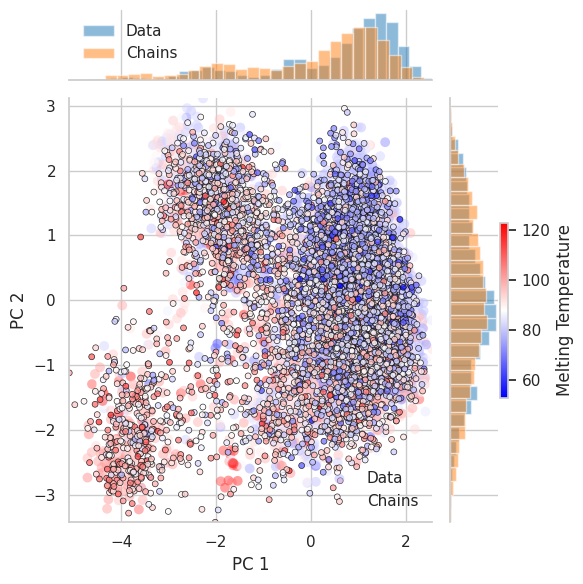

In [55]:
import seaborn as sns
import pandas as pd
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

fig = plt.figure(figsize=(8, 8), dpi=100)

# Put into a single DataFrame if desired (not strictly necessary)
df1 = pd.DataFrame({'x': data_proj[:, 0], 'y': data_proj[:, 1], 'label': labels_data, 'group': 'Data'})
df2 = pd.DataFrame({'x': chains_proj[:, 0], 'y': chains_proj[:, 1], 'label': labels_chains, 'group': 'Chains'})
df = pd.concat([df1, df2], ignore_index=True)

# Build a JointGrid for shared axes and custom marginals
sns.set_theme(style="whitegrid")
g = sns.JointGrid(x="x", y="y", data=df, height=6)

# Create a single colormap normalization across both datasets
vmin = df['label'].min()
vmax = df['label'].max()
norm = Normalize(vmin=vmin, vmax=vmax)
cmap = plt.get_cmap("bwr")

# Plot scatter for each dataset separately on the same joint axes
ax = g.ax_joint
sc1 = ax.scatter(df1['x'], df1['y'], c=cmap(norm(df1['label'])), s=50, edgecolor='none', alpha=0.5, label='Data')
sc2 = ax.scatter(df2['x'], df2['y'], c=cmap(norm(df2['label'])), s=18, edgecolor='black', alpha=0.8, label='Chains', linewidth=0.5)

ax.legend(frameon=False, loc="best")
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")

# Add a single colorbar representing the continuous variable
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cb = plt.colorbar(sm, ax=g.ax_marg_y, pad=0.02)
cb.set_label("Melting Temperature")

# Marginal histograms for each dataset, overlaid
# Top (x) histogram
g.ax_marg_x.hist(df1['x'], bins=30, density=True, color="#1f77b4", alpha=0.5, label='Data')
g.ax_marg_x.hist(df2['x'], bins=30, density=True, color="#ff7f0e", alpha=0.5, label='Chains')
g.ax_marg_x.set_xlim(df['x'].min(), df['x'].max())
g.ax_marg_x.set_ylabel("Density")
g.ax_marg_x.legend(frameon=False, loc="best")

# Right (y) histogram
g.ax_marg_y.hist(df1['y'], bins=30, density=True, color="#1f77b4", alpha=0.5, orientation="horizontal")
g.ax_marg_y.hist(df2['y'], bins=30, density=True, color="#ff7f0e", alpha=0.5, orientation="horizontal")
g.ax_marg_y.set_ylim(df['y'].min(), df['y'].max())
g.ax_marg_y.set_xlabel("Density")

plt.tight_layout()
plt.show()


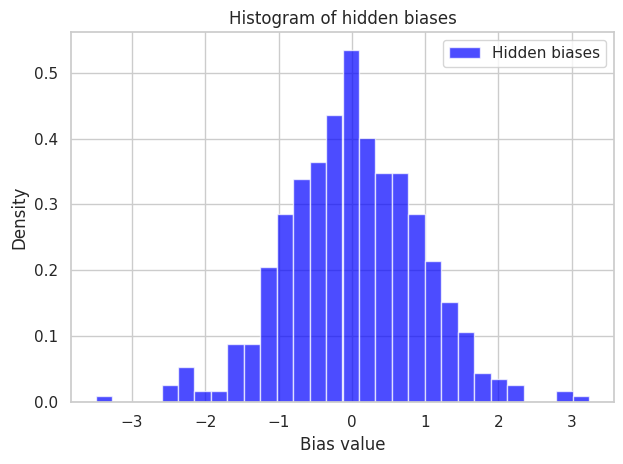

In [57]:
plt.hist(
    rbm.hidden_layer.bias.detach().cpu().numpy(),
    bins=30,
    density=True,
    alpha=0.7,
    color="blue",
    label="Hidden biases",
);
plt.legend()
plt.xlabel("Bias value")
plt.ylabel("Density")
plt.title("Histogram of hidden biases")
plt.tight_layout()

In [11]:
plt.hist(
    rbm.hidden_layer.scale.detach().cpu().numpy(),
    bins=30,
    alpha=0.7,
    color="blue",
    label="Hidden scales",
)
plt.legend()
plt.xlabel("Scale value")
plt.ylabel("Density")
plt.title("Histogram of hidden scales")
plt.tight_layout()

AttributeError: 'BernoulliLayer' object has no attribute 'scale'

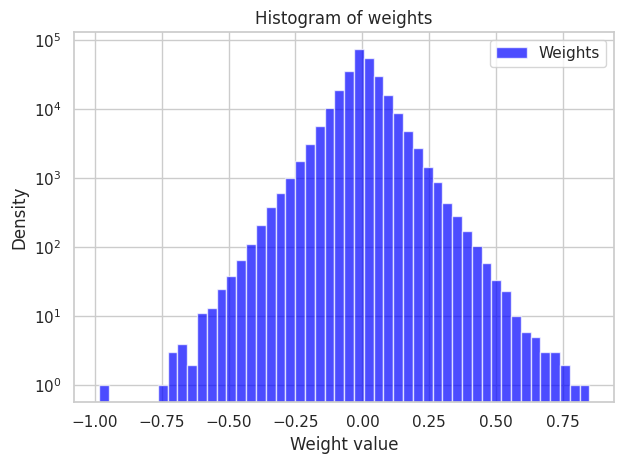

In [58]:
plt.hist(
    rbm.weight_matrix.detach().cpu().flatten().numpy(),
    bins=50,
    alpha=0.7,
    color="blue",
    label="Weights",
)
plt.legend()
plt.xlabel("Weight value")
plt.ylabel("Density")
plt.title("Histogram of weights")
plt.yscale("log")
plt.tight_layout()

### Sample unconditioned

In [59]:
samples = rbm.sample(gibbs_steps=10000, num_samples=10000)
samples_proj = pca.transform(samples["visible"].view(len(samples["visible"]), -1).cpu().numpy())
samples_labels = train_dataset.unstandardize_labels(samples["label"]).cpu().numpy()[:, 0]

df3 = pd.DataFrame({'x': samples_proj[:, 0], 'y': samples_proj[:, 1], 'label': samples_labels, 'group': 'Samples'})

<Figure size 800x800 with 0 Axes>

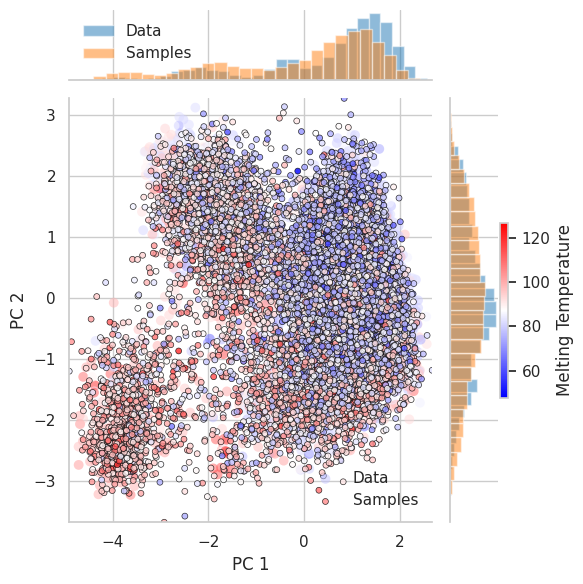

In [60]:
fig = plt.figure(figsize=(8, 8), dpi=100)
df = pd.concat([df1, df3], ignore_index=True)

# Build a JointGrid for shared axes and custom marginals
sns.set_theme(style="whitegrid")
g = sns.JointGrid(x="x", y="y", data=df, height=6)

# Create a single colormap normalization across both datasets
vmin = df['label'].min()
vmax = df['label'].max()
norm = Normalize(vmin=vmin, vmax=vmax)
cmap = plt.get_cmap("bwr")

# Plot scatter for each dataset separately on the same joint axes
ax = g.ax_joint
sc1 = ax.scatter(df1['x'], df1['y'], c=cmap(norm(df1['label'])), s=50, edgecolor='none', alpha=0.5, label='Data')
sc2 = ax.scatter(df3['x'], df3['y'], c=cmap(norm(df3['label'])), s=18, edgecolor='black', alpha=0.8, label='Samples', linewidth=0.5)

ax.legend(frameon=False, loc="best")
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")

# Add a single colorbar representing the continuous variable
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cb = plt.colorbar(sm, ax=g.ax_marg_y, pad=0.02)
cb.set_label("Melting Temperature")

# Marginal histograms for each dataset, overlaid
# Top (x) histogram
g.ax_marg_x.hist(df1['x'], bins=30, density=True, color="#1f77b4", alpha=0.5, label='Data')
g.ax_marg_x.hist(df3['x'], bins=30, density=True, color="#ff7f0e", alpha=0.5, label='Samples')
g.ax_marg_x.set_xlim(df['x'].min(), df['x'].max())
g.ax_marg_x.set_ylabel("Density")
g.ax_marg_x.legend(frameon=False, loc="best")

# Right (y) histogram
g.ax_marg_y.hist(df1['y'], bins=30, density=True, color="#1f77b4", alpha=0.5, orientation="horizontal")
g.ax_marg_y.hist(df3['y'], bins=30, density=True, color="#ff7f0e", alpha=0.5, orientation="horizontal")
g.ax_marg_y.set_ylim(df['y'].min(), df['y'].max())
g.ax_marg_y.set_xlabel("Density")

plt.tight_layout()
plt.show()

In [61]:
pi = get_freq_single_point(samples["visible"])
pij = get_freq_two_points(samples["visible"])
rho, slope = get_correlation_two_points(fij, pij, fi, pi)
print(f"Correlation: {rho}, Slope: {slope}")

Correlation: 0.9650219082832336, Slope: 1.0025966167449951


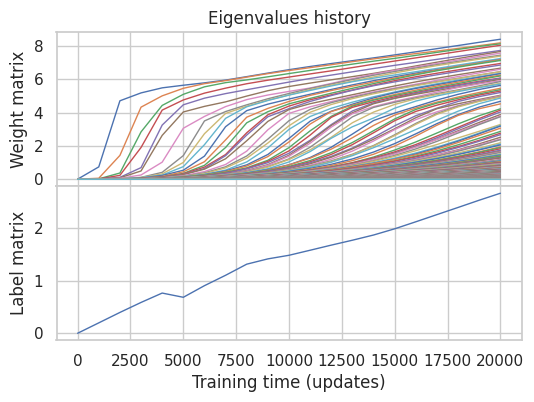

In [62]:
updates, eigenvalues = get_eigenvalues_history(checkpoint_dir, target_matrix="weight_matrix", device=device, dtype=dtype)
updates, eigenvalues_labels = get_eigenvalues_history(checkpoint_dir, target_matrix="label_matrix", device=device, dtype=dtype)

# Plot the eigenvalues history. first row is the weight matrix, second row is the label matrix.
fig, ax = plt.subplots(2, 1, figsize=(6, 4), sharex=True, gridspec_kw={'hspace': 0})
ax[0].plot(updates, eigenvalues, lw=1)
ax[1].plot(updates, eigenvalues_labels, lw=1)
ax[1].set_xlabel("Training time (updates)")
ax[0].set_ylabel("Weight matrix")
ax[1].set_ylabel("Label matrix")
ax[0].set_title("Eigenvalues history");

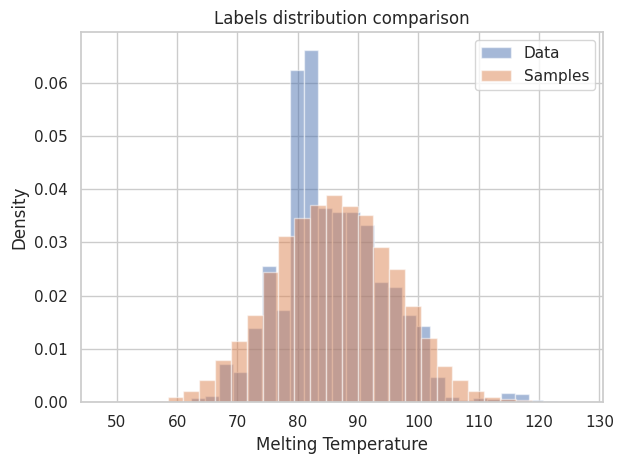

In [63]:
# compare labels histograms
plt.hist(labels_data, bins=30, density=True, alpha=0.5, label="Data")
plt.hist(samples_labels, bins=30, density=True, alpha=0.5, label="Samples")
plt.legend()
plt.xlabel("Melting Temperature")
plt.ylabel("Density")
plt.title("Labels distribution comparison")
plt.tight_layout()
plt.show()

### Conditioned sampling

In [64]:
cond_chains = rbm.sample_conditioned(
    gibbs_steps=10000,
    targets=train_dataset.labels_one_hot,
)

In [65]:
cond_chains_proj = pca.transform(cond_chains["visible"].view(len(cond_chains["visible"]), -1).cpu().numpy())
cond_chains_labels = labels_data
df4 = pd.DataFrame({'x': cond_chains_proj[:, 0], 'y': cond_chains_proj[:, 1], 'label': cond_chains_labels, 'group': 'Cond. Chains'})

<Figure size 800x800 with 0 Axes>

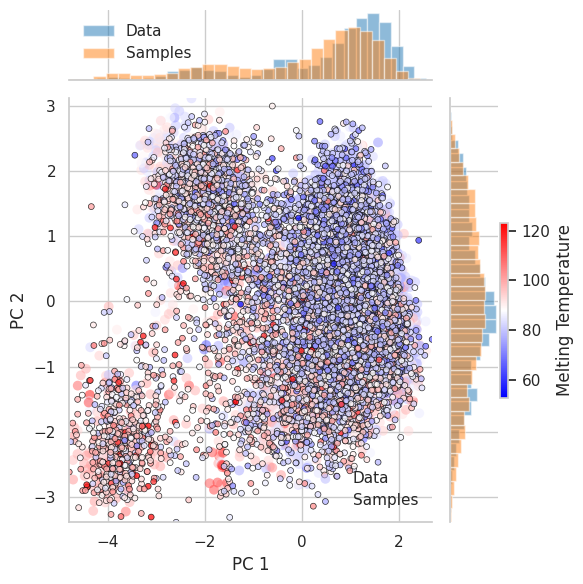

In [66]:
fig = plt.figure(figsize=(8, 8), dpi=100)
df = pd.concat([df1, df4], ignore_index=True)

# Build a JointGrid for shared axes and custom marginals
sns.set_theme(style="whitegrid")
g = sns.JointGrid(x="x", y="y", data=df, height=6)

# Create a single colormap normalization across both datasets
vmin = df['label'].min()
vmax = df['label'].max()
norm = Normalize(vmin=vmin, vmax=vmax)
cmap = plt.get_cmap("bwr")

# Plot scatter for each dataset separately on the same joint axes
ax = g.ax_joint
sc1 = ax.scatter(df1['x'], df1['y'], c=cmap(norm(df1['label'])), s=50, edgecolor='none', alpha=0.5, label='Data')
sc2 = ax.scatter(df4['x'], df4['y'], c=cmap(norm(df4['label'])), s=18, edgecolor='black', alpha=0.8, label='Samples', linewidth=0.5)

ax.legend(frameon=False, loc="best")
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")

# Add a single colorbar representing the continuous variable
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cb = plt.colorbar(sm, ax=g.ax_marg_y, pad=0.02)
cb.set_label("Melting Temperature")

# Marginal histograms for each dataset, overlaid
# Top (x) histogram
g.ax_marg_x.hist(df1['x'], bins=30, density=True, color="#1f77b4", alpha=0.5, label='Data')
g.ax_marg_x.hist(df4['x'], bins=30, density=True, color="#ff7f0e", alpha=0.5, label='Samples')
g.ax_marg_x.set_xlim(df['x'].min(), df['x'].max())
g.ax_marg_x.set_ylabel("Density")
g.ax_marg_x.legend(frameon=False, loc="best")

# Right (y) histogram
g.ax_marg_y.hist(df1['y'], bins=30, density=True, color="#1f77b4", alpha=0.5, orientation="horizontal")
g.ax_marg_y.hist(df4['y'], bins=30, density=True, color="#ff7f0e", alpha=0.5, orientation="horizontal")
g.ax_marg_y.set_ylim(df['y'].min(), df['y'].max())
g.ax_marg_y.set_xlabel("Density")

plt.tight_layout()
plt.show()

In [67]:
pi = get_freq_single_point(cond_chains["visible"])
pij = get_freq_two_points(cond_chains["visible"])
rho, slope = get_correlation_two_points(fij, pij, fi, pi)
print(f"Correlation: {rho}, Slope: {slope}")

Correlation: 0.9617395997047424, Slope: 0.966180682182312


In [68]:
from annadca.utils.functions import batched_mm_right

def predict_continuous_labels(rbm, visible):
    """Approximate predictions of the labels when the label is a Gaussian variable"""
    h = rbm.mean_hidden_activation(visible, torch.tensor([0.], device=visible.device, dtype=visible.dtype).unsqueeze(1))
    I_l = batched_mm_right(rbm.label_matrix, h) # (batch_size, num_classes)
    mean = (I_l + rbm.label_layer.bias) / rbm.label_layer.scale
    return mean.squeeze()

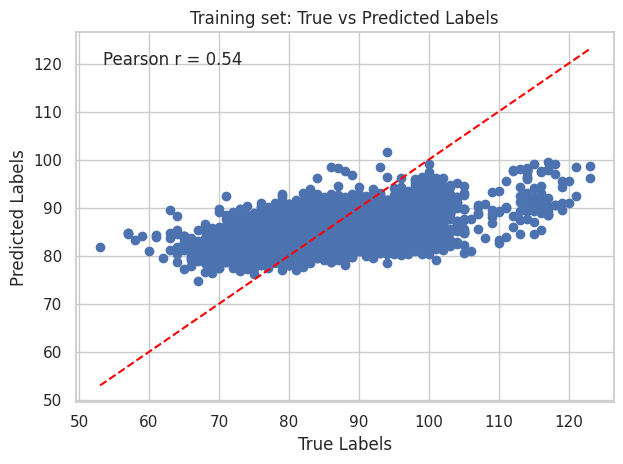

In [69]:
predictions = predict_continuous_labels(rbm, visible=train_dataset.data_one_hot)
predictions = train_dataset.unstandardize_labels(predictions).cpu().numpy()
targets = train_dataset.unstandardize_labels(train_dataset.labels_one_hot).squeeze().cpu().numpy()

# scatter plot and pearson correlation

plt.scatter(targets, predictions)
x = np.linspace(targets.min(), targets.max(), 100)
plt.plot(x, x, color='red', linestyle='--')
plt.xlabel("True Labels")
plt.ylabel("Predicted Labels")
plt.title("Training set: True vs Predicted Labels")
corr = np.corrcoef(targets, predictions)[0, 1]
plt.annotate(f'Pearson r = {corr:.2f}', xy=(0.05, 0.95), xycoords='axes fraction', fontsize=12, verticalalignment='top')
plt.tight_layout()

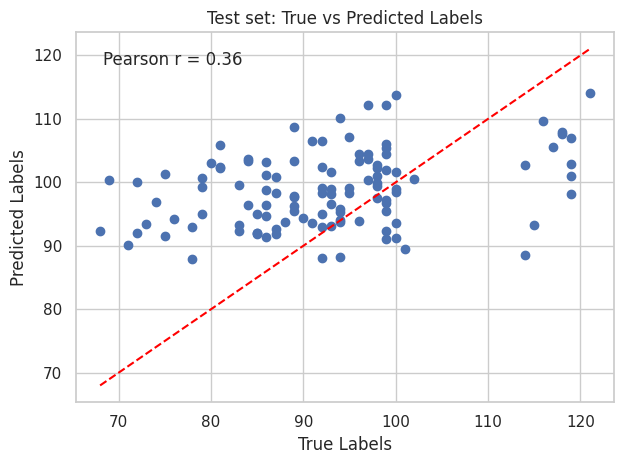

In [70]:
predictions = predict_continuous_labels(rbm, visible=test_dataset.data_one_hot)
predictions = test_dataset.unstandardize_labels(predictions).cpu().numpy()
targets = test_dataset.unstandardize_labels(test_dataset.labels_one_hot).squeeze().cpu().numpy()

# scatter plot and pearson correlation

plt.scatter(targets, predictions)
x = np.linspace(targets.min(), targets.max(), 100)
plt.plot(x, x, color='red', linestyle='--')
plt.xlabel("True Labels")
plt.ylabel("Predicted Labels")
plt.title("Test set: True vs Predicted Labels")
corr = np.corrcoef(targets, predictions)[0, 1]
plt.annotate(f'Pearson r = {corr:.2f}', xy=(0.05, 0.95), xycoords='axes fraction', fontsize=12, verticalalignment='top')
plt.tight_layout()

### Check energies

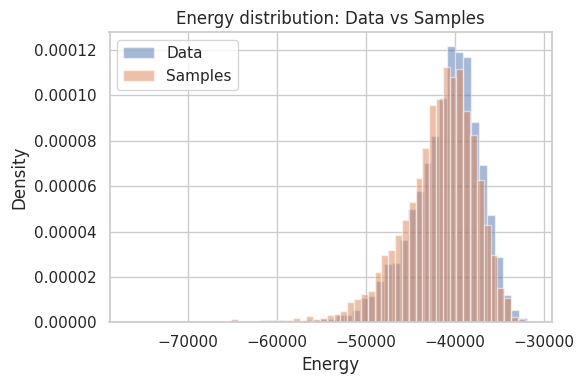

In [73]:
energy_data = rbm.compute_energy_visibles(data)
energy_samples = rbm.compute_energy_visibles(samples["visible"])

plt.figure(figsize=(6,4))
plt.hist(energy_data.cpu().numpy(), bins=50, density=True, alpha=0.5, label="Data")
plt.hist(energy_samples.cpu().numpy(), bins=50, density=True, alpha=0.5, label="Samples")
plt.xlabel("Energy")
plt.ylabel("Density")
plt.legend()
plt.title("Energy distribution: Data vs Samples")
plt.tight_layout()

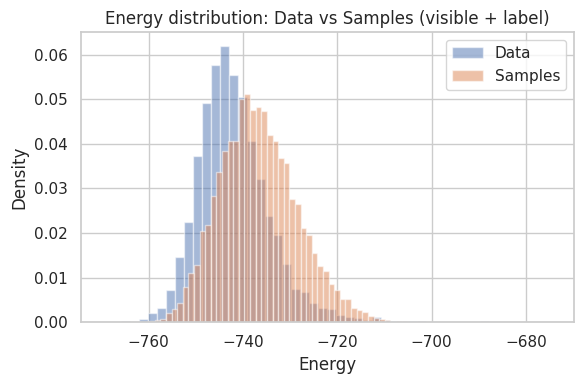

In [74]:
energy_visible_label_data = rbm.compute_energy_visibles_labels(data, train_dataset.labels_one_hot)
energy_visible_label_samples = rbm.compute_energy_visibles_labels(samples["visible"], samples["label"])

plt.figure(figsize=(6,4))
plt.hist(energy_visible_label_data.cpu().numpy(), bins=50, density=True, alpha=0.5, label="Data")
plt.hist(energy_visible_label_samples.cpu().numpy(), bins=50, density=True, alpha=0.5, label="Samples")
plt.xlabel("Energy")
plt.ylabel("Density")
plt.legend()
plt.title("Energy distribution: Data vs Samples (visible + label)")
plt.tight_layout()

KeyboardInterrupt: 

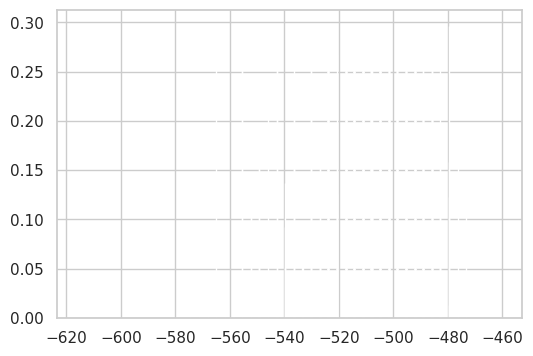

In [75]:
hidden_data = rbm.sample_hiddens(data, label=train_dataset.labels_one_hot)
energy_hidden_data = rbm.compute_energy_hiddens(hidden_data)
energy_hidden_samples = rbm.compute_energy_hiddens(samples["hidden"])

plt.figure(figsize=(6,4))
plt.hist(energy_hidden_data.cpu().numpy(), bins=50, density=True, alpha=0.5, label="Data")
plt.hist(energy_hidden_samples.cpu().numpy(), bins=50, density=True, alpha=0.5, label="Samples")
plt.xlabel("Energy")
plt.ylabel("Density")
plt.legend()
plt.title("Energy distribution: Hidden Data vs Hidden Samples")
plt.tight_layout()

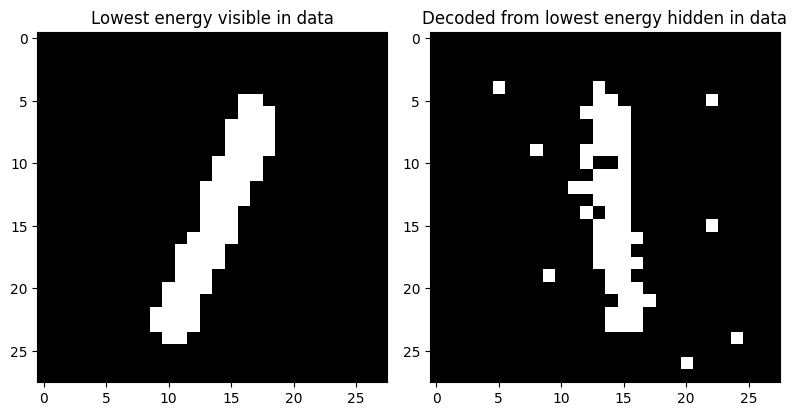

In [221]:
lowest_energy_hidden = hidden_data[energy_hidden_data.argmin()]
lowest_energy_hidden_decoded = rbm.sample_visibles(lowest_energy_hidden)
lowest_energy_visible = data[energy_data.argmin()]

fig, ax = plt.subplots(1, 2, figsize=(8,4))
ax[0].imshow(lowest_energy_visible.view(28,28).cpu(), cmap="gray")
ax[0].set_title("Lowest energy visible in data")
ax[1].imshow(lowest_energy_hidden_decoded.view(28,28).cpu(), cmap="gray")
ax[1].set_title("Decoded from lowest energy hidden in data")
fig.tight_layout()

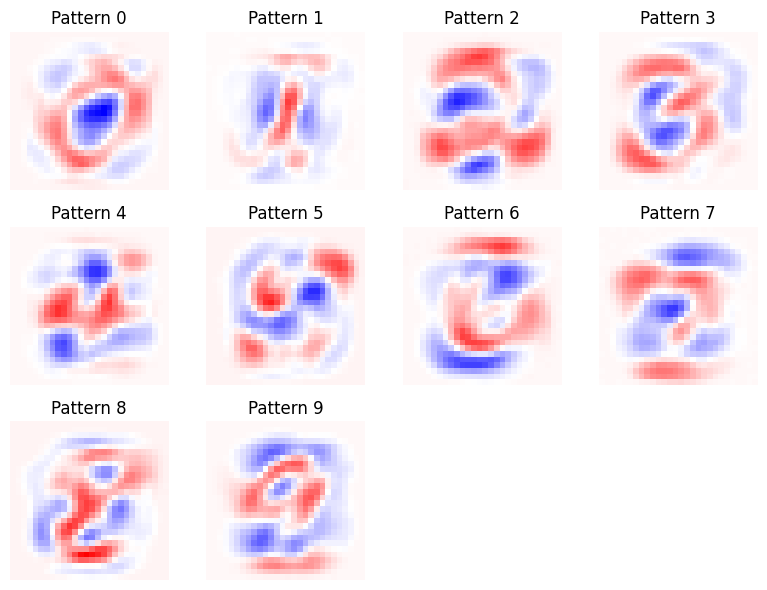

In [222]:
patterns = rbm.get_patterns()

plt.figure(figsize=(8,6))
num_patterns = patterns.shape[0]
for i in range(num_patterns):
    plt.subplot(int(np.ceil(num_patterns/4)), 4, i+1)
    plt.imshow(patterns[i].cpu().numpy().reshape(28,28), cmap='bwr', vmin=patterns.min(), vmax=patterns.max())
    plt.axis('off')
    plt.title(f'Pattern {i}')
plt.tight_layout()